In [1]:
# mounting the file to drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# setup cell, making sure the paths are correct

import glob
import os
import shutil
import subprocess

import h5py
import numpy as np

DRIVE_ZIP = "/content/drive/MyDrive/U-Net_Project/project_TransUNet.zip"
LOCAL_ZIP = "/content/project_TransUNet.zip"
DATA_DIR = "/content/data"
MARKER = f"{DATA_DIR}/.extract_ok"

LOCAL = f"{DATA_DIR}/project_TransUNet/data/Synapse"
LISTS = f"{DATA_DIR}/project_TransUNet/TransUNet/lists/lists_Synapse"


def verify_data() -> None:
    """Fully read every file, so a truncated or corrupted file is caught here."""
    train_files = sorted(glob.glob(f"{LOCAL}/train_npz/*.npz"))
    test_files = sorted(glob.glob(f"{LOCAL}/test_vol_h5/*.h5"))
    assert len(train_files) == 2211, f"expected 2211 train slices, found {len(train_files)}"
    assert len(test_files) == 12, f"expected 12 test volumes, found {len(test_files)}"
    for name in ["train.txt", "test_vol.txt"]:
        assert os.path.exists(f"{LISTS}/{name}"), f"missing list file: {name}"

    for f in train_files:
        with np.load(f) as d:
            d["image"], d["label"]   # reading both arrays fully also checks the zip CRC
    for f in test_files:
        with h5py.File(f, "r") as h:
            h["image"][0], h["label"][0]  # it only checks the first slice
    print("Verification passed.")


if os.path.exists(MARKER):
    print("Data already extracted and verified, skipping.")
else:
    shutil.rmtree(DATA_DIR, ignore_errors=True)   # remove any half-extracted leftovers
    os.makedirs(DATA_DIR)
    shutil.copy(DRIVE_ZIP, LOCAL_ZIP)             # copy the zip to local disk first
    subprocess.run(["unzip", "-q", LOCAL_ZIP, "-d", DATA_DIR], check=True)
    verify_data()
    open(MARKER, "w").close()                     # written only after everything succeeded
    os.remove(LOCAL_ZIP)
    print("Extraction finished.")

Verification passed.
Extraction finished.


In [7]:
# calculating number of files

!ls "{LOCAL}/train_npz" | wc -l      # expected 2211
!ls "{LOCAL}/test_vol_h5" | wc -l    # expected 12

2211
12


In [45]:
import os
from pathlib import Path

train_files = sorted((Path(LOCAL) / "train_npz").glob("*.npz"))
test_files = sorted((Path(LOCAL) / "test_vol_h5").glob("*.h5"))

with open(f"{LISTS}/train.txt") as f:
    train_list = [line.strip() for line in f if line.strip()]
with open(f"{LISTS}/test_vol.txt") as f:
    test_list = [line.strip() for line in f if line.strip()]

on_disk_slices = {os.path.basename(p).replace(".npz", "") for p in train_files}
on_disk_volumes = {os.path.basename(p).replace(".npy.h5", "") for p in test_files}

cases = sorted({name.split("_slice")[0] for name in on_disk_slices})

print("train slices on disk :", len(train_files), "| in train.txt:", len(train_list))   # expected 2211 / 2211
print("train cases          :", len(cases))                                              # expected 18
print("test volumes on disk :", len(test_files), "| in test_vol.txt:", len(test_list))   # expected 12 / 12
print("train.txt matches disk:", set(train_list) == on_disk_slices)
print("test_vol.txt matches disk:", set(test_list) == on_disk_volumes)
print(cases)

train slices on disk : 2211 | in train.txt: 2211
train cases          : 18
test volumes on disk : 12 | in test_vol.txt: 12
train.txt matches disk: True
test_vol.txt matches disk: True
['case0005', 'case0006', 'case0007', 'case0009', 'case0010', 'case0021', 'case0023', 'case0024', 'case0026', 'case0027', 'case0028', 'case0030', 'case0031', 'case0033', 'case0034', 'case0037', 'case0039', 'case0040']


In [9]:
# verifying counts
import numpy as np

ORGANS = ["background", "aorta", "gallbladder", "kidney_l", "kidney_r",
          "liver", "pancreas", "spleen", "stomach"]

pixel_counts = np.zeros(256, dtype=np.int64)    # pixels per class (organ)
slice_counts = np.zeros(256, dtype=np.int64)    # number of slices where the class (organ) appears
best_slice = {}                                 # slice which we see the organ most
img_min, img_max = np.inf, -np.inf              # min, max brightness

for f in train_files:
    d = np.load(f)
    label = d["label"].astype(np.int64)
    img_min = min(img_min, d["image"].min())  # 0.0
    img_max = max(img_max, d["image"].max())  # 0.1

    counts = np.bincount(label.ravel(), minlength=256)  # counts the pixels by organ
    pixel_counts += counts                              # total pixel that the organ was seen
    slice_counts += (counts > 0)

    for k in range(1, 9):
        if counts[k] > best_slice.get(k, (0, None))[0]:
            best_slice[k] = (counts[k], f)               #after this part, each organ has a slice which it seems 'the most'

print("image range:", img_min, img_max)
print("unique labels:", np.nonzero(pixel_counts)[0].tolist())
for k in range(9):
    print(f"{k} {ORGANS[k]:12s} pixels={pixel_counts[k]:>12,d}  slices={slice_counts[k]}")

image range: 0.0 1.0
unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8]
0 background   pixels= 554,315,625  slices=2211
1 aorta        pixels=     922,056  slices=1215
2 gallbladder  pixels=     245,028  slices=228
3 kidney_l     pixels=   1,344,662  slices=543
4 kidney_r     pixels=   1,333,973  slices=547
5 liver        pixels=  14,192,919  slices=911
6 pancreas     pixels=     651,861  slices=430
7 spleen       pixels=   3,119,429  slices=532
8 stomach      pixels=   3,474,831  slices=594


In [46]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

data_root = Path(LOCAL)

sample = np.load(train_files[100])                         # choosing an arbitrary file
image, label = sample["image"], sample["label"]
print(image.shape, image.dtype, image.min(), image.max())
print("Labels in slice:", np.unique(label))

with h5py.File(data_root / "test_vol_h5" / "case0001.npy.h5", "r") as f:   #
    volume, volume_label = f["image"][:], f["label"][:]
print("Test volume:", volume.shape, volume_label.shape)
print("Test volume range:", volume.min(), volume.max())
print("Labels in test volume:", np.unique(volume_label))

(512, 512) float32 0.0 1.0
Labels in slice: [0. 1. 5.]
Test volume: (147, 512, 512) (147, 512, 512)
Test volume range: 0.0 1.0
Labels in test volume: [0 1 2 3 4 5 6 7 8]


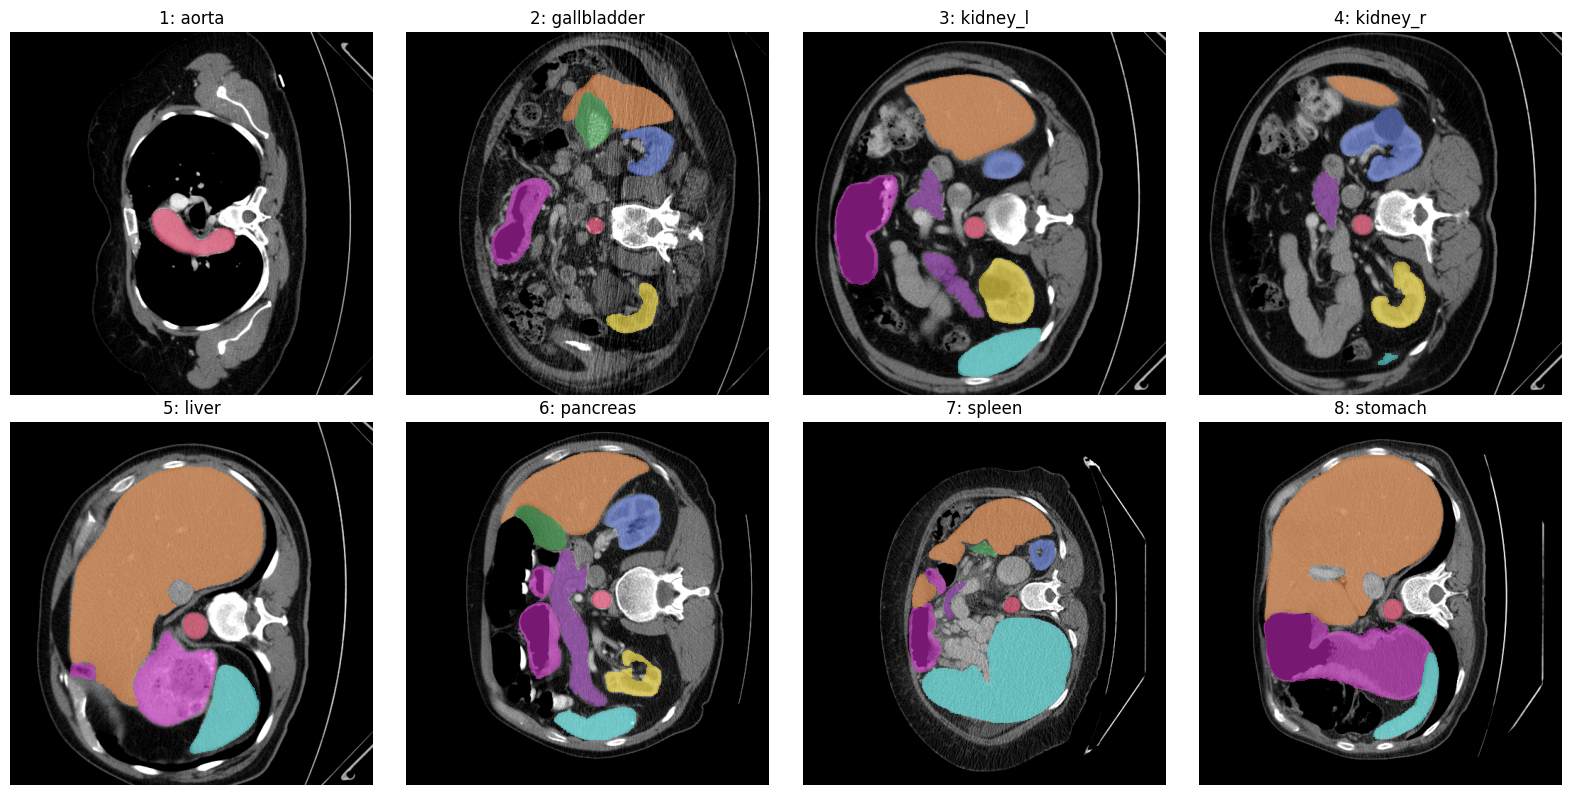

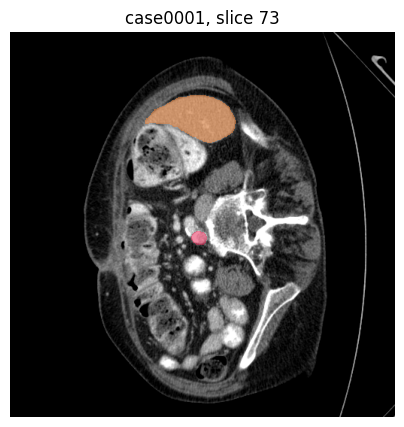

In [11]:
from matplotlib.colors import ListedColormap

ORGAN_CMAP = ListedColormap([
    (0, 0, 0, 0), "#e6194b", "#3cb44b", "#ffe119", "#4363d8",
    "#f58231", "#911eb4", "#46f0f0", "#f032e6",
])


def show_overlay(ax: plt.Axes, image: np.ndarray, mask: np.ndarray, title: str) -> None:
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.imshow(mask, cmap=ORGAN_CMAP, vmin=0, vmax=8, alpha=0.5, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")


# One slice per organ (the slice where that organ is largest)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, k in zip(axes.ravel(), range(1, 9)):
    d = np.load(best_slice[k][1])
    show_overlay(ax, d["image"], d["label"], f"{k}: {ORGANS[k]}")
plt.tight_layout()
plt.show()

# A test volume: middle slice with its full mask
mid = volume.shape[0] // 2
fig, ax = plt.subplots(figsize=(5, 5))
show_overlay(ax, volume[mid], volume_label[mid], f"case0001, slice {mid}")
plt.show()

Week 1 Step 2

In [12]:
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

data_root = Path(LOCAL)
train_files = sorted((data_root / "train_npz").glob("*.npz"))   # Path objects, as the page's code expects

case_ids = [path.stem.split("_")[0] for path in train_files]
splitter = GroupShuffleSplit(n_splits=1, test_size=3, random_state=42)
train_idx, val_idx = next(splitter.split(train_files, groups=case_ids))
val_cases = sorted({case_ids[i] for i in val_idx})
print("Validation cases:", val_cases)

train_cases = sorted({case_ids[i] for i in train_idx})
print("Train cases:", len(train_cases), train_cases)
print("Overlap:", set(train_cases) & set(val_cases))           # expected: set()
print("Train slices:", len(train_idx), "| Val slices:", len(val_idx), "| total:", len(train_idx) + len(val_idx))

Validation cases: ['case0005', 'case0006', 'case0026']
Train cases: 15 ['case0007', 'case0009', 'case0010', 'case0021', 'case0023', 'case0024', 'case0027', 'case0028', 'case0030', 'case0031', 'case0033', 'case0034', 'case0037', 'case0039', 'case0040']
Overlap: set()
Train slices: 1832 | Val slices: 379 | total: 2211


In [13]:
import json
import os

SPLIT_PATH = "/content/drive/MyDrive/U-Net_Project/split.json"
split_info = {"random_state": 42, "val_cases": val_cases, "train_cases": train_cases}

if os.path.exists(SPLIT_PATH):
    with open(SPLIT_PATH) as f:
        saved_split = json.load(f)
    assert val_cases == saved_split["val_cases"], "validation cases differ from the saved split"
    assert train_cases == saved_split["train_cases"], "train cases differ from the saved split"
    print("Split matches the saved split.json")
else:
    with open(SPLIT_PATH, "w") as f:
        json.dump(split_info, f, indent=2)
    print("saved", SPLIT_PATH)

Split matches the saved split.json


In [14]:
import torch
from scipy.ndimage import zoom
from torch.utils.data import DataLoader, Dataset


def random_rot_flip(image: np.ndarray, label: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Random 90-degree rotation and flip (flip with probability 0.5); the SAME k and axis are used for image and mask."""
    k = np.random.randint(0, 4)
    image = np.rot90(image, k)
    label = np.rot90(label, k)
    if np.random.rand() < 0.5:
        axis = np.random.randint(0, 2)
        image = np.flip(image, axis=axis)
        label = np.flip(label, axis=axis)
    return np.ascontiguousarray(image), np.ascontiguousarray(label)

In [15]:
class SynapseSliceDataset(Dataset):
    def __init__(self, files: list[Path], train: bool = False, img_size: int = 224) -> None:
        self.files = list(files)
        self.train = train
        self.img_size = img_size

    def __len__(self) -> int:
        return len(self.files)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        data = np.load(self.files[idx])
        image, label = data["image"], data["label"]

        if self.train:
            image, label = random_rot_flip(image, label)

        h, w = image.shape
        if (h, w) != (self.img_size, self.img_size):
            scale = (self.img_size / h, self.img_size / w)
            image = zoom(image, scale, order=3)    # cubic for the image
            label = zoom(label, scale, order=0)    # nearest for the mask, so labels stay valid class ids

        image = torch.from_numpy(image.astype(np.float32)).unsqueeze(0)   # (1, 224, 224)
        mask = torch.from_numpy(label.astype(np.int64))                   # (224, 224)
        return image, mask


train_ds = SynapseSliceDataset([train_files[i] for i in train_idx], train=True)
val_ds = SynapseSliceDataset([train_files[i] for i in val_idx], train=False)
print("train slices:", len(train_ds), "| val slices:", len(val_ds))   # expected 1832 | 379

img, msk = train_ds[0]
print(img.shape, img.dtype, msk.shape, msk.dtype)   # expected [1, 224, 224] float32, [224, 224] int64

train slices: 1832 | val slices: 379
torch.Size([1, 224, 224]) torch.float32 torch.Size([224, 224]) torch.int64


In [16]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=8,            # placeholder for this check, not a final choice
    shuffle=True,
    num_workers=2,
    generator=torch.Generator().manual_seed(SEED),
)

images, masks = next(iter(train_loader))
print("images:", images.shape, images.dtype, images.min().item(), images.max().item())
print("masks :", masks.shape, masks.dtype, torch.unique(masks).tolist())

images: torch.Size([8, 1, 224, 224]) torch.float32 -0.1521778702735901 1.1047877073287964
masks : torch.Size([8, 224, 224]) torch.int64 [0, 1, 3, 5, 7, 8]


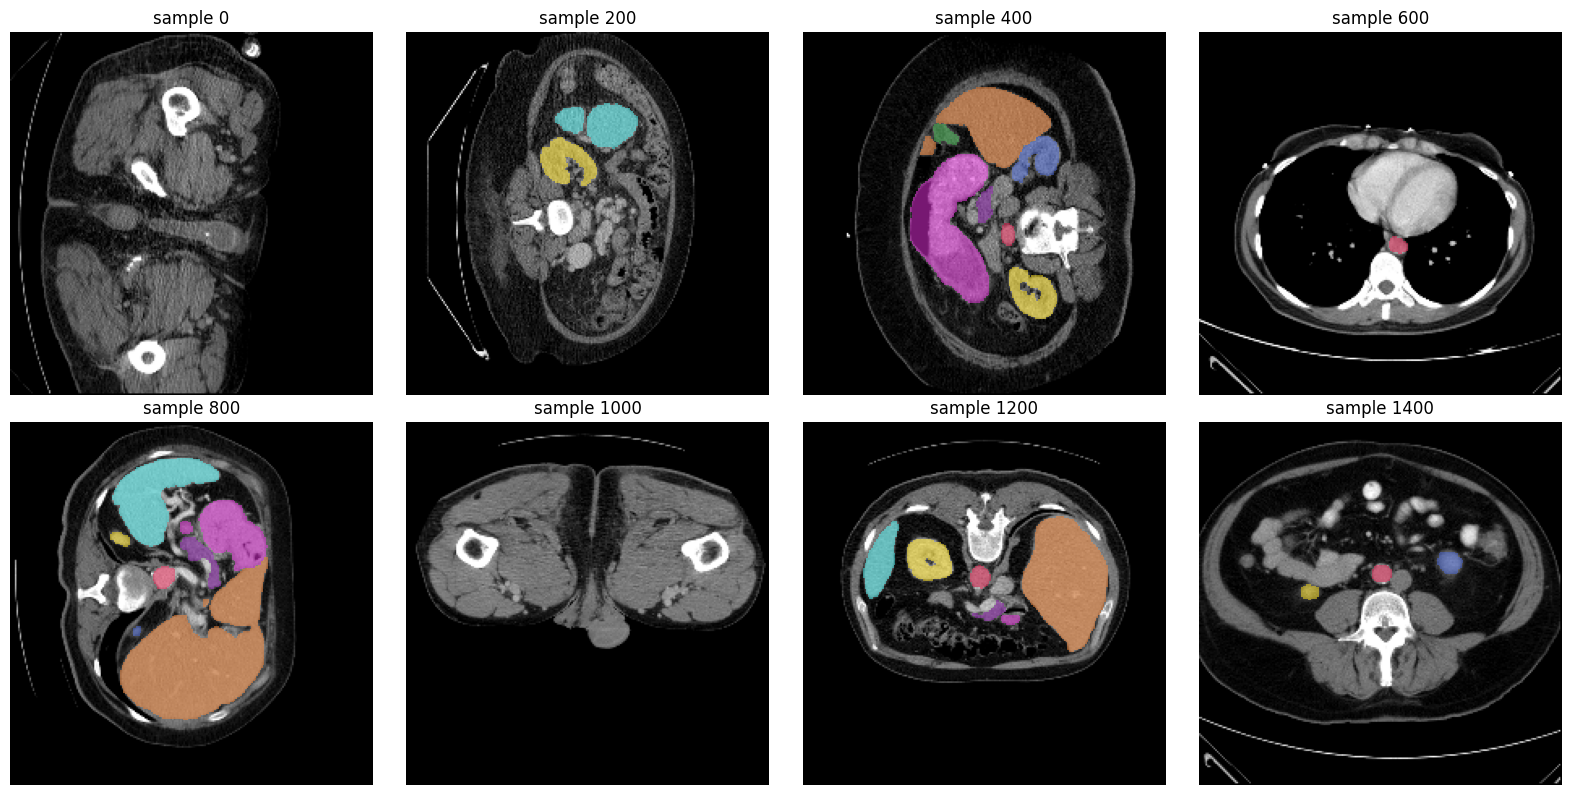

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), range(8)):
    img, msk = train_ds[i * 200]
    show_overlay(ax, img[0].numpy(), msk.numpy(), f"sample {i * 200}")
plt.tight_layout()
plt.show()

Week 1 Step 3

In [18]:
import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    """Conv2d -> BatchNorm -> ReLU, twice. Spatial size is preserved (kernel 3, padding 1)."""

    def __init__(self, in_ch: int, out_ch: int) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class EncoderBlock(nn.Module):
    """ConvBlock + MaxPool2d. Returns the features (for the skip connection) AND the pooled output."""

    def __init__(self, in_ch: int, out_ch: int) -> None:
        super().__init__()
        self.conv = ConvBlock(in_ch, out_ch)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.conv(x)
        return features, self.pool(features)


class DecoderBlock(nn.Module):
    """ConvTranspose2d for upsampling + concatenate the skip + ConvBlock."""

    def __init__(self, in_ch: int, out_ch: int) -> None:
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_ch * 2, out_ch)   # out_ch (upsampled) + out_ch (skip)

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)             # concatenate along channels
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels: int = 1, out_channels: int = 9, base: int = 64) -> None:
        super().__init__()
        self.enc1 = EncoderBlock(in_channels, base)        # 64
        self.enc2 = EncoderBlock(base, base * 2)           # 128
        self.enc3 = EncoderBlock(base * 2, base * 4)       # 256
        self.enc4 = EncoderBlock(base * 4, base * 8)       # 512
        self.bottleneck = ConvBlock(base * 8, base * 16)   # 1024
        self.dec4 = DecoderBlock(base * 16, base * 8)      # 512
        self.dec3 = DecoderBlock(base * 8, base * 4)       # 256
        self.dec2 = DecoderBlock(base * 4, base * 2)       # 128
        self.dec1 = DecoderBlock(base * 2, base)           # 64
        self.final = nn.Conv2d(base, out_channels, kernel_size=1)   # 9 channels, raw logits

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        s1, x = self.enc1(x)
        s2, x = self.enc2(x)
        s3, x = self.enc3(x)
        s4, x = self.enc4(x)
        x = self.bottleneck(x)
        x = self.dec4(x, s4)
        x = self.dec3(x, s3)
        x = self.dec2(x, s2)
        x = self.dec1(x, s1)
        return self.final(x)    # no softmax / sigmoid: the loss applies softmax internally

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet(in_channels=1, out_channels=9, base=64).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

model.eval()
with torch.no_grad():
    test_input = torch.randn(2, 1, 224, 224, device=device)
    test_output = model(test_input)

print("input :", tuple(test_input.shape))
print("output:", tuple(test_output.shape), test_output.dtype)
assert test_output.shape == (2, 9, 224, 224), "Shape mismatch!"
print("Forward pass OK")

Total parameters: 31,042,889
input : (2, 1, 224, 224)
output: (2, 9, 224, 224) torch.float32
Forward pass OK


Week 1 Step 4

In [20]:
# configurations

from dataclasses import dataclass
from pathlib import Path


@dataclass(frozen=True)
class SegConfig:
    data_root: Path = Path("Synapse")
    output_dir: Path = Path("outputs/synapse_unet")
    num_classes: int = 9
    image_size: int = 224
    batch_size: int = 16
    lr: float = 1e-4
    weight_decay: float = 1e-4
    epochs: int = 100
    seed: int = 42


# Only the two paths are overridden for Colab: data on local disk, outputs on Drive
CONFIG = SegConfig(
    data_root=Path(LOCAL),
    output_dir=Path("/content/drive/MyDrive/U-Net_Project/outputs/synapse_unet"),
)
CONFIG.output_dir.mkdir(parents=True, exist_ok=True)
print(CONFIG)

SegConfig(data_root=PosixPath('/content/data/project_TransUNet/data/Synapse'), output_dir=PosixPath('/content/drive/MyDrive/U-Net_Project/outputs/synapse_unet'), num_classes=9, image_size=224, batch_size=16, lr=0.0001, weight_decay=0.0001, epochs=100, seed=42)


In [21]:
import torch
import torch.nn.functional as F


def soft_dice_loss(logits: torch.Tensor, target: torch.Tensor, num_classes: int, eps: float = 1e-5) -> torch.Tensor:
    probs = torch.softmax(logits.float(), dim=1)
    one_hot = F.one_hot(target, num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = (probs * one_hot).sum(dims)
    denominator = probs.sum(dims) + one_hot.sum(dims)
    dice_per_class = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice_per_class.mean()


def seg_loss(logits: torch.Tensor, target: torch.Tensor, num_classes: int) -> torch.Tensor:
    return 0.5 * F.cross_entropy(logits, target) + 0.5 * soft_dice_loss(logits, target, num_classes)

# validation count, using this count for the report
def accumulate_dice_counts(
    pred: torch.Tensor, target: torch.Tensor, num_classes: int, counts: torch.Tensor
) -> None:
    for organ in range(1, num_classes):
        pred_mask, true_mask = pred == organ, target == organ
        counts[organ, 0] += (pred_mask & true_mask).sum()
        counts[organ, 1] += pred_mask.sum() + true_mask.sum()

In [22]:
import random

import numpy as np
from torch.utils.data import DataLoader
from tqdm.auto import tqdm


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CONFIG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# Rebuilt with CONFIG.batch_size (16); the Step 2 loader used the placeholder 8
train_loader = DataLoader(
    train_ds, batch_size=CONFIG.batch_size, shuffle=True, num_workers=2,
    generator=torch.Generator().manual_seed(CONFIG.seed),
)
val_loader = DataLoader(val_ds, batch_size=CONFIG.batch_size, shuffle=False, num_workers=2)

model = UNet(in_channels=1, out_channels=CONFIG.num_classes, base=64).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG.lr, weight_decay=CONFIG.weight_decay)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


@torch.no_grad()
def validate(model: torch.nn.Module, loader: DataLoader) -> tuple[float, float, list[float]]:
    """Validation loss, mean Dice over the 8 organs, and Dice per organ (counts accumulated over ALL slices)."""
    model.eval()
    total_loss, n = 0.0, 0
    counts = torch.zeros(CONFIG.num_classes, 2, dtype=torch.float64, device=device)
    for images, masks in tqdm(loader, desc="val", leave=False):
        images, masks = images.to(device), masks.to(device)
        with torch.autocast("cuda", enabled=use_amp):
            logits = model(images)
            loss = seg_loss(logits, masks, CONFIG.num_classes)
        total_loss += loss.item() * images.size(0)
        n += images.size(0)
        accumulate_dice_counts(logits.argmax(dim=1), masks, CONFIG.num_classes, counts)
    dice_per_organ = 2 * counts[1:, 0] / counts[1:, 1]
    return total_loss / n, dice_per_organ.mean().item(), dice_per_organ.cpu().tolist()

In [28]:
# training

import json
from dataclasses import asdict

NUM_EPOCHS = CONFIG.epochs   # 100, the value on the task page, i trained 10 and 30 epochs before that so it resumes from that point
SAVE_LAST_EVERY = 5
RESUME = True
out = CONFIG.output_dir
history = {"train_loss": [], "val_loss": [], "val_mean_dice": []}
best_dice, best_epoch, start_epoch = -1.0, -1, 0

if RESUME and (out / "last.pt").exists():
    ckpt = torch.load(out / "last.pt", map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scaler.load_state_dict(ckpt["scaler"])
    history, best_dice, best_epoch = ckpt["history"], ckpt["best_dice"], ckpt["best_epoch"]
    start_epoch = ckpt["epoch"] + 1
    print(f"resumed from epoch {start_epoch}")

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()
    running, seen = 0.0, 0
    for images, masks in tqdm(train_loader, desc=f"epoch {epoch + 1}/{NUM_EPOCHS} train", leave=False):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=use_amp):
            logits = model(images)
            loss = seg_loss(logits, masks, CONFIG.num_classes)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * images.size(0)   # .item(): keep a number, not the whole graph
        seen += images.size(0)

    train_loss = running / seen
    val_loss, val_dice, per_organ = validate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_mean_dice"].append(val_dice)

    is_best = val_dice > best_dice
    if is_best:
        best_dice, best_epoch = val_dice, epoch
        torch.save(
            {
                "model": model.state_dict(),
                "epoch": epoch,
                "val_mean_dice": val_dice,
                "per_organ_dice": per_organ,
                "config": {k: str(v) for k, v in asdict(CONFIG).items()},
            },
            out / "best.pt",
        )

    (out / "history.json").write_text(
        json.dumps({"history": history, "best_epoch": best_epoch, "best_val_mean_dice": best_dice})
    )
    if (epoch + 1) % SAVE_LAST_EVERY == 0 or epoch + 1 == NUM_EPOCHS:
        torch.save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(),
                "history": history,
                "best_dice": best_dice,
                "best_epoch": best_epoch,
                "epoch": epoch,
            },
            out / "last.pt",
        )

    print(
        f"epoch {epoch + 1:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} "
        f"| val mean Dice {val_dice:.4f}{'  <- best' if is_best else ''}"
    )

resumed from epoch 30


epoch 31/100 train:   0%|          | 0/115 [00:00<?, ?it/s]

val:   0%|          | 0/24 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>
    Traceback (most recent call last):
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
: can only test a child process    
if w.is_alive():
  File "/usr/lib/

epoch  31 | train loss 0.1145 | val loss 0.4377 | val mean Dice 0.4184


...

epoch 100/100 train:   0%|          | 0/115 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val:   0%|          | 0/24 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7944081fade0>

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
AssertionError    : self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

epoch 100 | train loss 0.0630 | val loss 0.3821 | val mean Dice 0.6202  <- best


x ticks: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]


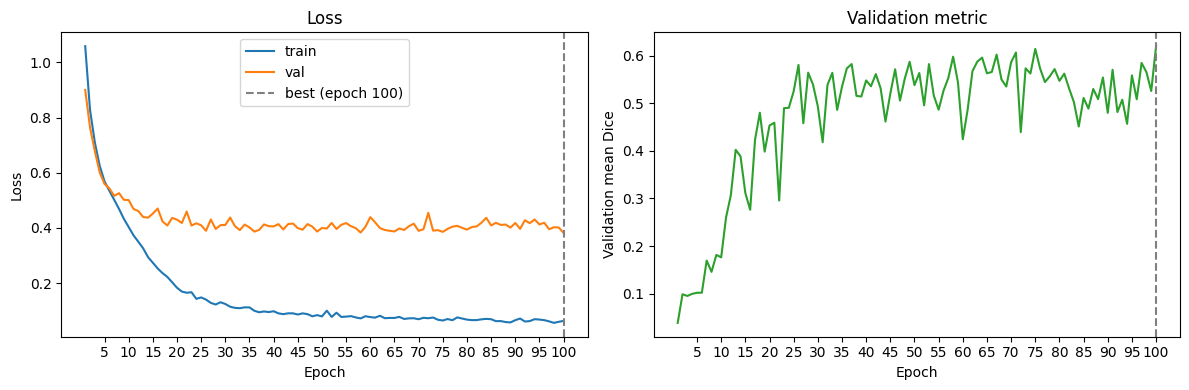

best epoch: 100 | val mean Dice: 0.6202
aorta        0.8617
gallbladder  0.6452
kidney_l     0.5785
kidney_r     0.2908
liver        0.9232
pancreas     0.2492
spleen       0.7779
stomach      0.6350


In [29]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path


def plot_training_curves(history: dict[str, list[float]], output_path: Path) -> None:
    epochs = range(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmax(history["val_metric"])) + 1   # changed from the guide: best = highest validation mean Dice (Step 4)
    ticks = list(epochs) if len(epochs) <= 20 else list(range(5, len(epochs) + 1, 5))
    print("x ticks:", ticks)                                  # diagnostic: proves this version of the function is running

    fig, (loss_ax, metric_ax) = plt.subplots(1, 2, figsize=(12, 4))
    loss_ax.plot(epochs, history["train_loss"], label="train")
    loss_ax.plot(epochs, history["val_loss"], label="val")
    loss_ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best (epoch {best_epoch})")
    loss_ax.set(xlabel="Epoch", ylabel="Loss", title="Loss")
    loss_ax.legend()

    metric_ax.plot(epochs, history["val_metric"], color="tab:green")
    metric_ax.axvline(best_epoch, color="gray", linestyle="--")
    metric_ax.set(xlabel="Epoch", ylabel="Validation mean Dice", title="Validation metric")

    for ax in (loss_ax, metric_ax):
        ax.set_xticks(ticks)                                  # one tick per epoch (for runs of up to 20 epochs)

    fig.tight_layout()
    fig.savefig(output_path, dpi=200)


plot_history = {
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "val_metric": history["val_mean_dice"],
}
plot_training_curves(plot_history, out / "curves.png")
plt.show()

best = torch.load(out / "best.pt", map_location="cpu")
assert best["epoch"] == int(np.argmax(history["val_mean_dice"])), "marked epoch differs from best.pt"
print("best epoch:", best["epoch"] + 1, "| val mean Dice:", round(best["val_mean_dice"], 4))
for name, d in zip(ORGANS[1:], best["per_organ_dice"]):
    print(f"{name:12s} {d:.4f}")

In [32]:
print("epochs trained:", len(history["val_mean_dice"]))
print("best epoch (by val mean Dice):", int(np.argmax(history["val_mean_dice"])) + 1,
      "| best val mean Dice:", round(max(history["val_mean_dice"]), 4))
for e, (tl, vl, vd) in enumerate(zip(history["train_loss"], history["val_loss"], history["val_mean_dice"]), 1):
    print(f"epoch {e:3d} | train {tl:.4f} | val {vl:.4f} | val Dice {vd:.4f}")

epochs trained: 100
best epoch (by val mean Dice): 100 | best val mean Dice: 0.6202
epoch   1 | train 1.0587 | val 0.9000 | val Dice 0.0384
epoch   2 | train 0.8275 | val 0.7643 | val Dice 0.0985
epoch   3 | train 0.7095 | val 0.6782 | val Dice 0.0950
epoch   4 | train 0.6253 | val 0.6014 | val Dice 0.0995
epoch   5 | train 0.5688 | val 0.5594 | val Dice 0.1017
epoch   6 | train 0.5345 | val 0.5434 | val Dice 0.1019
epoch   7 | train 0.5021 | val 0.5164 | val Dice 0.1695
epoch   8 | train 0.4689 | val 0.5261 | val Dice 0.1457
epoch   9 | train 0.4330 | val 0.5020 | val Dice 0.1813
epoch  10 | train 0.4032 | val 0.5008 | val Dice 0.1762
epoch  11 | train 0.3731 | val 0.4687 | val Dice 0.2598
epoch  12 | train 0.3498 | val 0.4612 | val Dice 0.3069
epoch  13 | train 0.3259 | val 0.4395 | val Dice 0.4023
epoch  14 | train 0.2944 | val 0.4372 | val Dice 0.3886
epoch  15 | train 0.2739 | val 0.4519 | val Dice 0.3114
epoch  16 | train 0.2531 | val 0.4703 | val Dice 0.2761
epoch  17 | train 0.

Week 1 Step 5

In [48]:
out = CONFIG.output_dir
print(out)
print(sorted(p.name for p in out.iterdir()))
if (out / "last.pt").exists():
    ck = torch.load(out / "last.pt", map_location="cpu")
    print("last.pt epoch:", ck["epoch"] + 1, "| best val mean Dice so far:", round(ck["best_dice"], 4))

/content/drive/MyDrive/U-Net_Project/outputs/synapse_unet
['best.pt', 'curves.png', 'history.json', 'kidney_check_unet.csv', 'last.pt', 'test_metrics_unet.csv', 'test_overlays.png', 'test_pred_unet']
last.pt epoch: 100 | best val mean Dice so far: 0.6202


In [34]:
best = torch.load(out / "best.pt", map_location=device)
model.load_state_dict(best["model"])
print("loaded best.pt from epoch", best["epoch"] + 1)   # expected 100


@torch.no_grad()
def confusion_matrix_val(model: torch.nn.Module, loader: DataLoader) -> torch.Tensor:
    model.eval()
    cm = torch.zeros(9, 9, dtype=torch.int64, device=device)   # rows: true class, columns: predicted class
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        with torch.autocast("cuda", enabled=use_amp):
            pred = model(images).argmax(dim=1)
        cm += torch.bincount((masks * 9 + pred).flatten(), minlength=81).reshape(9, 9)
    return cm.cpu()


cm = confusion_matrix_val(model, val_loader)
for k in range(1, 9):
    row = cm[k].double() / cm[k].sum()
    top = torch.topk(row, 3)
    desc = ", ".join(f"{ORGANS[int(i)]} {v:.1%}" for v, i in zip(top.values, top.indices))
    print(f"true {ORGANS[k]:12s} -> predicted as: {desc}")

loaded best.pt from epoch 100
true aorta        -> predicted as: aorta 81.5%, background 18.4%, spleen 0.0%
true gallbladder  -> predicted as: gallbladder 57.1%, background 37.1%, liver 5.3%
true kidney_l     -> predicted as: kidney_l 61.0%, background 25.5%, kidney_r 12.6%
true kidney_r     -> predicted as: kidney_l 42.6%, background 25.2%, kidney_r 20.0%
true liver        -> predicted as: liver 92.8%, background 6.0%, spleen 0.7%
true pancreas     -> predicted as: background 83.5%, pancreas 15.1%, liver 0.9%
true spleen       -> predicted as: spleen 78.9%, liver 11.6%, background 8.4%
true stomach      -> predicted as: stomach 51.8%, background 42.7%, liver 2.0%


In [35]:
# trying to find why dice of the kidney_r is lower

cm_d = cm.double()
tp_union = cm_d[3:5, 3:5].sum()                              # true kidney (either side) predicted as a kidney (either side)
true_union = cm_d[3:5].sum()                                 # all true kidney pixels
pred_union = cm_d[:, 3:5].sum()                              # all predicted kidney pixels
print(f"merged kidney Dice: {(2 * tp_union / (true_union + pred_union)).item():.4f}")
print(f"kidney_l Dice {(2 * cm_d[3, 3] / (cm_d[3].sum() + cm_d[:, 3].sum())).item():.4f} | "
      f"kidney_r Dice {(2 * cm_d[4, 4] / (cm_d[4].sum() + cm_d[:, 4].sum())).item():.4f}")   # should match 0.5785 and 0.2908

merged kidney Dice: 0.7796
kidney_l Dice 0.5785 | kidney_r Dice 0.2908


In [36]:
!pip install -q medpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 12.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 44.1 MB/s eta 0:00:00


In [37]:
# loading the best checkpoint

import h5py
import pandas as pd
from medpy import metric
from tqdm.auto import tqdm

ckpt = torch.load(CONFIG.output_dir / "best.pt", map_location=device)
model.load_state_dict(ckpt["model"])
model.eval()
print("loaded best.pt from epoch", ckpt["epoch"] + 1, "| val mean Dice", round(ckpt["val_mean_dice"], 4))   # expected 100 | 0.6202

loaded best.pt from epoch 100 | val mean Dice 0.6202


In [38]:
def dice_hd95(pred: np.ndarray, gt: np.ndarray) -> tuple[float, float]:
    pred, gt = pred > 0, gt > 0
    if pred.sum() > 0 and gt.sum() > 0:
        return metric.binary.dc(pred, gt), metric.binary.hd95(pred, gt)
    if pred.sum() > 0 and gt.sum() == 0:
        return 1.0, 0.0
    return 0.0, 0.0


@torch.no_grad()
def predict_volume(model: torch.nn.Module, volume: np.ndarray, size: int = 224, batch: int = 32) -> np.ndarray:
    """Slice-by-slice prediction at size x size; the label map is resized back with nearest interpolation."""
    n, h, w = volume.shape
    small = np.stack([zoom(s, (size / h, size / w), order=3) for s in volume]).astype(np.float32)   # cubic, same as training
    preds = []
    for i in range(0, n, batch):
        x = torch.from_numpy(small[i:i + batch]).unsqueeze(1).to(device)
        with torch.autocast("cuda", enabled=use_amp):
            preds.append(model(x).argmax(dim=1).cpu())
    pred = torch.cat(preds).numpy().astype(np.uint8)                        # (n, 224, 224)
    return np.stack([zoom(p, (h / size, w / size), order=0) for p in pred])  # nearest back to (n, h, w)


test_paths = sorted((Path(LOCAL) / "test_vol_h5").glob("*.npy.h5"))
assert len(test_paths) == 12, len(test_paths)
pred_dir = CONFIG.output_dir / "test_pred_unet"
pred_dir.mkdir(parents=True, exist_ok=True)

rows, special = [], []
for p in tqdm(test_paths, desc="test volumes"):
    case_id = p.name.replace(".npy.h5", "")
    with h5py.File(p, "r") as f:
        image, gt = f["image"][:], f["label"][:]
    pred = predict_volume(model, image)
    np.savez_compressed(pred_dir / f"{case_id}.npz", pred=pred)
    for k in range(1, 9):
        n_pred, n_gt = int((pred == k).sum()), int((gt == k).sum())
        if n_pred == 0 or n_gt == 0:
            special.append((case_id, ORGANS[k], n_pred, n_gt))
        d, h = dice_hd95(pred == k, gt == k)       # once per organ, on the whole 3D volume
        rows.append({"case_id": case_id, "method": "unet", "organ": ORGANS[k], "dice": float(d), "hd95": float(h)})

results = pd.DataFrame(rows)
assert len(results) == 12 * 8
print("organ/case pairs where the prediction or the ground truth is empty:", len(special))
for s in special:
    print("  (case, organ, predicted voxels, true voxels):", s)

test volumes:   0%|          | 0/12 [00:00<?, ?it/s]

organ/case pairs where the prediction or the ground truth is empty: 1
  (case, organ, predicted voxels, true voxels): ('case0035', 'gallbladder', 4745, 0)


In [39]:
results.to_csv(CONFIG.output_dir / "test_metrics_unet.csv", index=False)   # columns: case_id, method, organ, dice, hd95

per_organ = results.groupby("organ")[["dice", "hd95"]].mean().reindex(ORGANS[1:])
dsc, hd95 = per_organ["dice"].mean() * 100, per_organ["hd95"].mean()

columns = {"aorta": "Aorta", "gallbladder": "Gallbladder", "kidney_l": "Kidney (L)", "kidney_r": "Kidney (R)",
           "liver": "Liver", "pancreas": "Pancreas", "spleen": "Spleen", "stomach": "Stomach"}
table = pd.DataFrame(
    [{"Method": "U-Net (ours)", "DSC": round(dsc, 2), "HD95": round(hd95, 2),
      **{columns[o]: round(per_organ.loc[o, "dice"] * 100, 2) for o in columns}}]
)
print(table.to_string(index=False))

per_case = results.groupby("case_id")["dice"].mean() * 100
assert np.isclose(per_case.mean(), dsc)   # mean of per-case means == mean of per-organ means (balanced 12 x 8)
print(f"per-case mean DSC: {per_case.mean():.2f} +- {per_case.std():.2f} (std over 12 cases, ddof=1)")
print(per_case.round(2).sort_values().to_string())

      Method   DSC  HD95  Aorta  Gallbladder  Kidney (L)  Kidney (R)  Liver  Pancreas  Spleen  Stomach
U-Net (ours) 69.12 54.21  85.34        57.27       74.71       59.56  89.49     46.21    72.1    68.29
per-case mean DSC: 69.12 +- 12.21 (std over 12 cases, ddof=1)
case_id
case0003    45.90
case0008    54.51
case0025    60.40
case0029    62.90
case0004    63.39
case0001    68.98
case0038    69.69
case0036    76.21
case0032    77.08
case0022    81.99
case0002    82.52
case0035    85.87


In [49]:
import pandas as pd

results = pd.read_csv(CONFIG.output_dir / "test_metrics_unet.csv")   # columns: case_id, method, organ, dice, hd95
gb = results[results["organ"] == "gallbladder"].set_index("case_id")

print(gb[["dice", "hd95"]].round(3).to_string())
print()
print("gallbladder Dice, protocol (12 cases)         :", round(gb["dice"].mean() * 100, 2))
print("gallbladder Dice, excluding case0035 (11 cases):", round(gb.drop("case0035")["dice"].mean() * 100, 2))
print("gallbladder HD95, protocol (12 cases)         :", round(gb["hd95"].mean(), 2))
print("gallbladder HD95, excluding case0035 (11 cases):", round(gb.drop("case0035")["hd95"].mean(), 2))

           dice     hd95
case_id                 
case0001  0.193  233.109
case0002  0.666   50.763
case0003  0.196  235.996
case0004  0.390   62.267
case0008  0.896    1.414
case0022  0.728   41.049
case0025  0.838   36.332
case0029  0.475    7.000
case0032  0.896    1.414
case0035  1.000    0.000
case0036  0.593    4.000
case0038  0.000   67.753

gallbladder Dice, protocol (12 cases)         : 57.27
gallbladder Dice, excluding case0035 (11 cases): 53.38
gallbladder HD95, protocol (12 cases)         : 61.76
gallbladder HD95, excluding case0035 (11 cases): 67.37


In [41]:
print(results.groupby("organ")["hd95"].mean().reindex(ORGANS[1:]).round(2).to_string())
print()
print(results.pivot(index="case_id", columns="organ", values="hd95")[ORGANS[1:]].round(1).to_string())

organ
aorta           14.82
gallbladder     61.76
kidney_l       100.26
kidney_r        75.13
liver           70.57
pancreas        19.33
spleen          66.66
stomach         25.16

organ     aorta  gallbladder  kidney_l  kidney_r  liver  pancreas  spleen  stomach
case_id                                                                           
case0001   10.6        233.1       1.4       8.1  113.5       9.8     8.1     26.6
case0002   23.2         50.8       1.0       2.0   12.1       9.3     2.0     19.3
case0003   81.9        236.0     149.0     163.9  118.6      35.5   222.0     61.8
case0004    2.0         62.3     190.7     194.0   32.0      30.9     8.2     31.8
case0008   29.0          1.4     141.8     141.9   32.0      14.0     8.0     40.8
case0022    1.4         41.0     143.4     164.2   37.6      10.2    10.8      4.0
case0025   12.6         36.3     155.1      38.1   75.8       9.5    13.2     18.0
case0029    2.0          7.0     148.0     132.8   46.7      36.8   16

In [42]:
#post analysis

rows = []
for p in test_paths:
    case_id = p.name.replace(".npy.h5", "")
    with h5py.File(p, "r") as f:
        gt = f["label"][:]
    pred = np.load(pred_dir / f"{case_id}.npz")["pred"]

    row = {"case_id": case_id}
    for k, name in ((3, "kidney_l"), (4, "kidney_r")):
        pk = pred[gt == k]                                   # predictions on the true voxels of this kidney
        row[f"{name}: correct %"] = round(100 * (pk == k).mean(), 1)
        row[f"{name}: as other kidney %"] = round(100 * (pk == (7 - k)).mean(), 1)   # 3 <-> 4
    # both kidneys merged into one class: removes the left/right ambiguity
    d, h = dice_hd95(np.isin(pred, [3, 4]), np.isin(gt, [3, 4]))
    row["merged kidney Dice %"] = round(100 * d, 1)
    row["merged kidney HD95"] = round(float(h), 1)
    rows.append(row)

kidney_check = pd.DataFrame(rows).set_index("case_id")
print(kidney_check.to_string())
print()
print(kidney_check.mean().round(1).to_string())

          kidney_l: correct %  kidney_l: as other kidney %  kidney_r: correct %  kidney_r: as other kidney %  merged kidney Dice %  merged kidney HD95
case_id                                                                                                                                               
case0001                 93.9                          0.2                 71.5                          0.0                  89.0                 5.8
case0002                 96.2                          0.0                 94.9                          0.0                  94.6                 1.4
case0003                 72.2                         23.3                  9.9                         85.2                  84.6                64.8
case0004                 88.9                          6.7                 40.4                         23.5                  86.3                 6.0
case0008                  5.2                          0.0                 19.5               

In [43]:
   kidney_check.to_csv(CONFIG.output_dir / "kidney_check_unet.csv")

worst : case0003, slice 144, mean DSC 45.90
median: case0038, slice 75, mean DSC 69.69
best  : case0035, slice 75, mean DSC 85.87


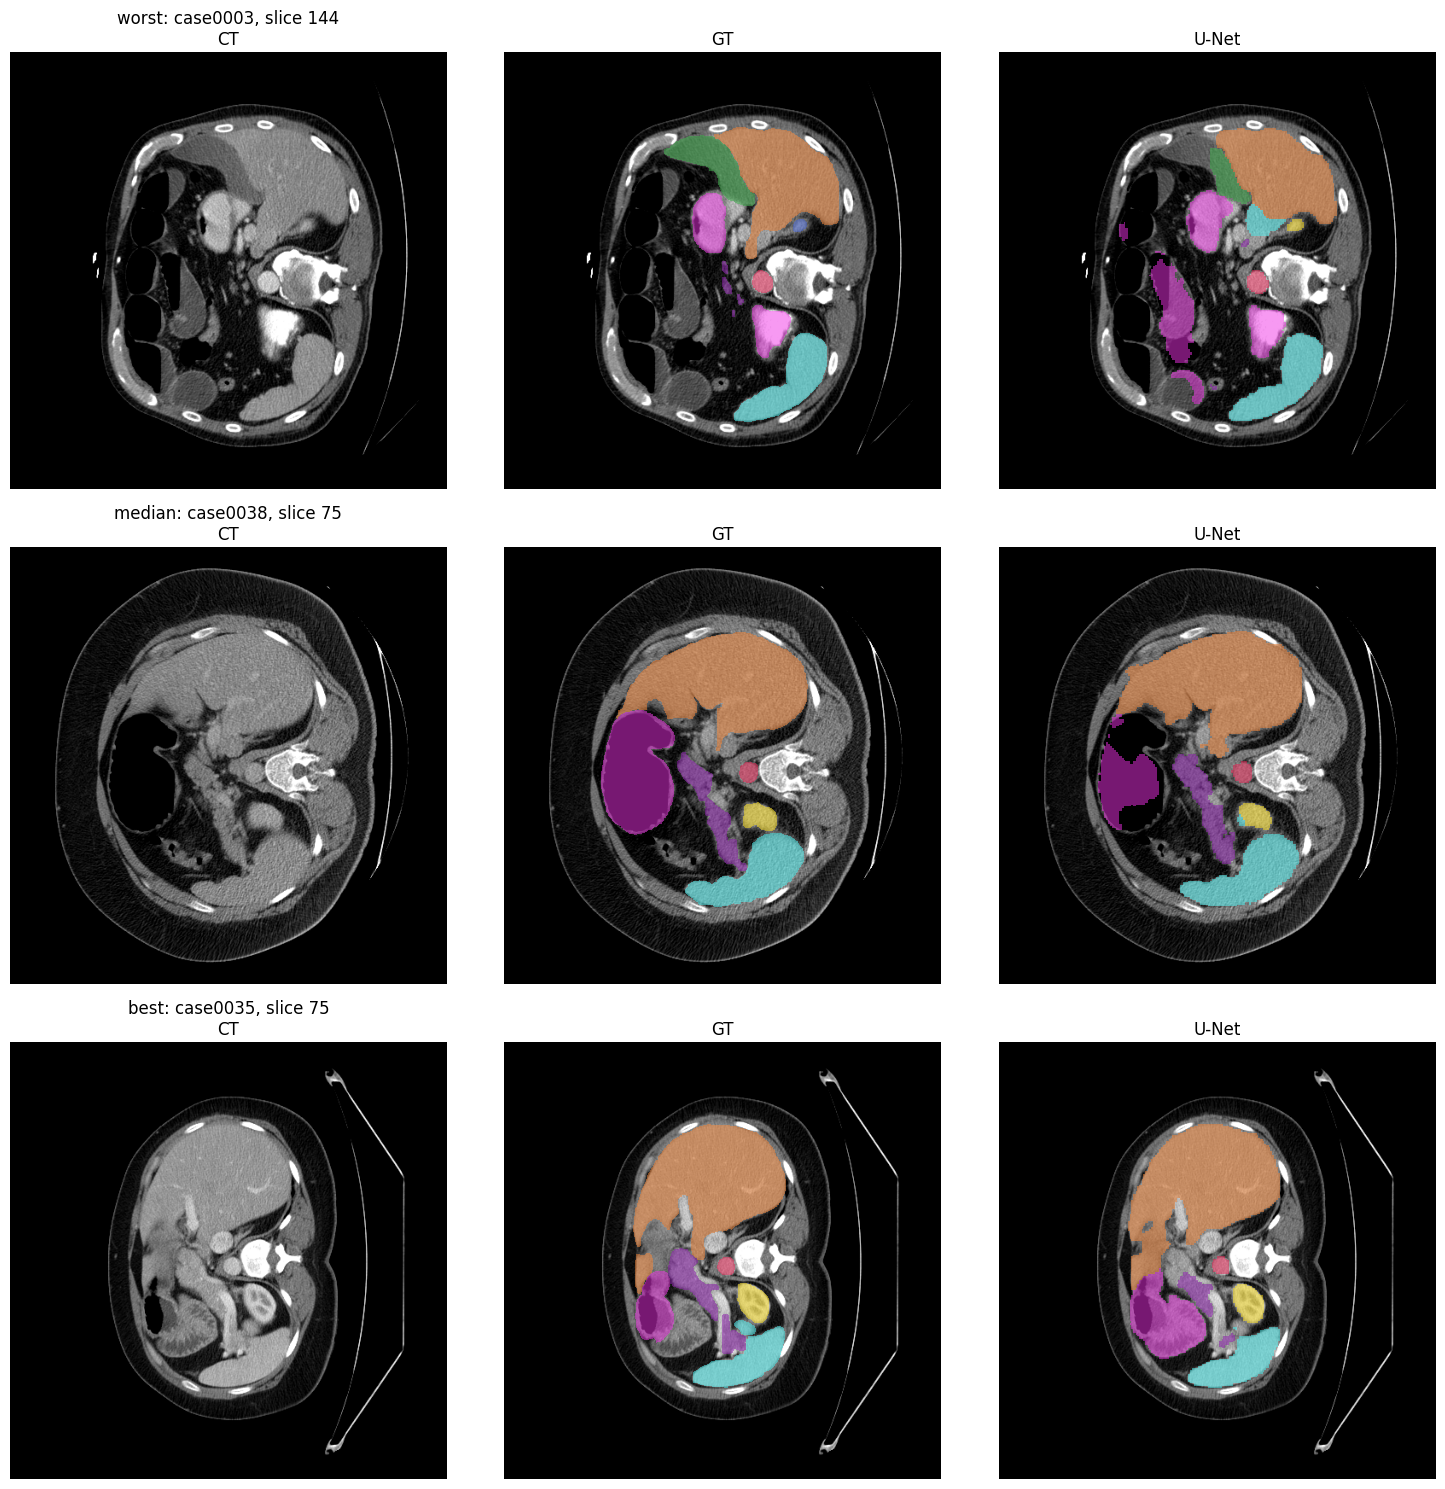

In [44]:
import matplotlib.pyplot as plt

order = per_case.sort_values().index.tolist()
chosen = {"worst": order[0], "median": order[len(order) // 2], "best": order[-1]}

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for r, (tag, case_id) in enumerate(chosen.items()):
    with h5py.File(Path(LOCAL) / "test_vol_h5" / f"{case_id}.npy.h5", "r") as f:
        image, gt = f["image"][:], f["label"][:]
    pred = np.load(pred_dir / f"{case_id}.npz")["pred"]
    hard = ((gt == 2) | (gt == 6)).sum(axis=(1, 2))      # gallbladder or pancreas voxels per slice
    s = int(hard.argmax())
    assert hard[s] > 0
    print(f"{tag:6s}: {case_id}, slice {s}, mean DSC {per_case[case_id]:.2f}")   # record these in the issue comment
    axes[r, 0].imshow(image[s], cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"{tag}: {case_id}, slice {s}\nCT")
    axes[r, 0].axis("off")
    show_overlay(axes[r, 1], image[s], gt[s], "GT")
    show_overlay(axes[r, 2], image[s], pred[s], "U-Net")
plt.tight_layout()
plt.savefig(CONFIG.output_dir / "test_overlays.png", dpi=200)
plt.show()